# Privacy-Preserving Federated Learning on ISIC 2019 — DermaFedNet + Secure FedAvg
PyTorch + Flower 1.39 (simulation). Runs in a VS Code Jupyter notebook with the Anaconda kernel `fl-isic`.

**Custom model — DermaFedNet:** ImageNet-pretrained ConvNeXt-Tiny encoder → CBAM channel+spatial attention
→ two branches: (a) GeM pooling, (b) 2-layer Transformer encoder over the 8×8 feature tokens (global context)
→ fused MLP classifier. A hybrid CNN–Transformer designed for dermoscopic lesions.

**Privacy layer (every round):**
1. Key setup: every client and the server own an X25519 key pair; only public keys are shared.
2. Downlink: the server encrypts the global model with AES-256-GCM and sends a SHA-256 digest;
   each client verifies the digest and decrypts.
3. Uplink: each client fixed-point encodes its weighted update (n_k · w_k), adds pairwise random masks
   (seeds from X25519 key agreement between clients), hashes it with SHA-256 and encrypts it with
   AES-256-GCM using a key shared only with the server.
4. Server: decrypts, verifies the SHA-256 digest of every client, and sums the masked updates.
   The pairwise masks cancel exactly in the sum, so the server obtains Σ n_k·w_k (→ FedAvg) but never
   sees any individual client's weights (secure aggregation).

**Schedule:** 10 federated rounds × up to 50 local epochs per client (local early stopping keeps the
best local epoch). Everything is printed per round (per client LOCAL vs GLOBAL) and saved to OUTPUT_DIR.

First run a smoke test: SUBSET_FRACTION = 0.1, NUM_ROUNDS = 2, LOCAL_EPOCHS = 2.

## 1. Imports

In [2]:
import os, sys, gc, io, math, json, time, copy, random, hashlib, warnings, logging, traceback
from collections import OrderedDict
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, classification_report, confusion_matrix,
                             roc_curve, auc)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from cryptography.hazmat.primitives import hashes, serialization
from cryptography.hazmat.primitives.asymmetric.x25519 import X25519PrivateKey, X25519PublicKey
from cryptography.hazmat.primitives.kdf.hkdf import HKDF
from cryptography.hazmat.primitives.ciphers.aead import AESGCM

import flwr
from flwr.app import Array, ArrayRecord, ConfigRecord, Context, Message, MetricRecord, RecordDict
from flwr.clientapp import ClientApp
from flwr.serverapp import Grid, ServerApp
from flwr.serverapp.strategy import FedAvg
from flwr.simulation import run_simulation
from flwr.common.logger import FLOWER_LOGGER

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore", category=UserWarning)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torchvision {__import__('torchvision').__version__} | flwr {flwr.__version__}")
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Python 3.11.16 | torch 2.9.1+cu126 | torchvision 0.24.1+cu126 | flwr 1.39.0
CUDA available: True | NVIDIA GeForce RTX 4090


## 2. Configuration — edit only this cell

In [3]:
# ---------- Paths ----------
LOCAL_DATA_DIR = r"F:\rakib\dataset"                     # ISIC 2019 (class folders MEL, NV, ... or CSV)
OUTPUT_DIR = Path("./fl_secure_iid_outputs").resolve()        # everything is saved here
CACHE_DIR  = Path("./isic_cache_288").resolve()           # resized copy of the images (created once)

# ---------- Data ----------
SUBSET_FRACTION = 1.0           # smoke test: 0.1
IMG_SIZE   = 256                # model input (must be a multiple of 32)
CACHE_SIZE = 288                # images resized once (shorter side) -> much faster training
VAL_FRAC, TEST_FRAC = 0.10, 0.20
LOCAL_VAL_FRAC = 0.10           # each client keeps 10% of its data for local validation / early stopping

# ---------- Federated setup ----------
NUM_CLIENTS     = 5
PARTITION       = "iid"   # "dirichlet" (non-IID, realistic) or "iid" (usually higher accuracy)
DIRICHLET_ALPHA = 0.5           # smaller = more heterogeneous clients
NUM_ROUNDS      = 50            # federated rounds
LOCAL_EPOCHS    = 50            # maximum local epochs per client per round
LOCAL_EARLY_STOP = True         # stop a client's local training when its local-val loss stops improving
LOCAL_PATIENCE  = 6             # ... after this many epochs without improvement (best epoch is kept)
SELECT_METRIC   = "acc"         # best global round chosen on server-val: "acc" or "bal_acc" (ISIC official)

# ---------- Model / optimisation ----------
PRETRAINED   = True             # ImageNet-pretrained ConvNeXt-Tiny encoder (strongly recommended)
BATCH_SIZE   = 32               # reduce to 16 if CUDA runs out of memory
LR_BACKBONE  = 1e-4             # AdamW, encoder
LR_HEAD      = 1e-3             # AdamW, CBAM + Transformer + classifier (randomly initialised)
LR_MIN_FACTOR = 0.05            # cosine decay within each round's local epochs down to 5% of the round LR
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
USE_CLASS_WEIGHTS = True        # square-root inverse-frequency weights per client (imbalanced ISIC)
USE_AMP = True                  # mixed precision on GPU
USE_TTA = True                  # test-time augmentation (4 flips) for the final test report

# ---------- Privacy ----------
FIXED_POINT_BITS = 24           # fixed-point precision for masked secure aggregation (2^-24)

# ---------- Saving / logging ----------
SAVE_EVERY_ROUND = True         # save the global model after every round (needed for RESUME)
RESUME = True                   # if a run was interrupted, continue from the last saved round
LOCAL_PRINT_EVERY = 5           # print a client's local epoch every N epochs (+ first/best/last)
QUIET_FLOWER_LOGS = True        # hide Flower's own INFO logs (our detailed logs are printed instead)

# ---------- Hardware ----------
NUM_GPUS = torch.cuda.device_count()
CLIENT_NUM_GPUS = 1.0 if NUM_GPUS else 0.0   # clients train one after another on the GPU
CLIENT_NUM_CPUS = max(1, min(4, os.cpu_count() or 1))
NUM_WORKERS = 0 if os.name == "nt" else min(2, CLIENT_NUM_CPUS)  # Windows: 0 (spawn-safe inside Ray)

SEED = 42
MODEL_NAME = "DermaFedNet"
os.environ.setdefault("PYTHONUTF8", "1")          # Ray worker processes on Windows print UTF-8 safely
os.environ.setdefault("PYTHONIOENCODING", "utf-8")

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

assert IMG_SIZE % 32 == 0, "IMG_SIZE must be a multiple of 32"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FLOWER_LOGGER.setLevel(logging.WARNING if QUIET_FLOWER_LOGS else logging.INFO)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LOG_FILE = OUTPUT_DIR / "run_log.txt"

def log(msg: str = ""):
    """Print to the notebook output and append to OUTPUT_DIR/run_log.txt."""
    print(msg, flush=True)
    with open(LOG_FILE, "a", encoding="utf-8") as f:
        f.write(msg + "\n")

CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in globals().items()
          if k.isupper() and isinstance(v, (int, float, str, bool, Path))}
with open(OUTPUT_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)
log(f"\n=== New session {time.strftime('%Y-%m-%d %H:%M:%S')} | device {DEVICE} | output {OUTPUT_DIR} ===")


=== New session 2026-10-07 18:50:16 | device cuda | output F:\Rakib\fl_secure_iid_outputs ===


## 3. Dataset discovery (class folders or ISIC ground-truth CSV, auto-detected)

Dataset: F:\rakib\dataset | 25331 images | 8 classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']


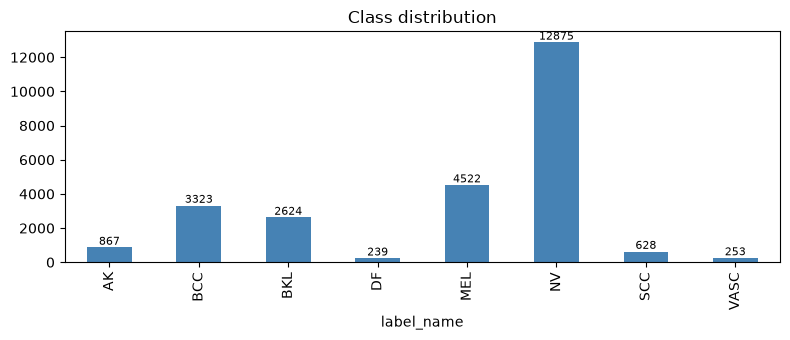

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def discover_dataset(root: Path) -> pd.DataFrame:
    """Return DataFrame[path, label_name]. Supports
    (a) class sub-folders at any depth (MEL/, NV/, ...; split folders are merged) and
    (b) ISIC_2019_Training_GroundTruth.csv (one-hot) + an image folder."""
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS]
    if not files:
        raise RuntimeError(f"No images found under {root}")
    csvs = [c for c in root.rglob("*.csv") if "groundtruth" in c.name.lower()]
    parents = pd.Series([p.parent.name for p in files])
    if csvs and parents.nunique() < 3:          # (b) CSV layout
        gt = pd.read_csv(csvs[0])
        cls_cols = [c for c in gt.columns if c not in ("image", "UNK") and gt[c].sum() > 0]
        gt["label_name"] = gt[cls_cols].idxmax(axis=1)
        by_stem = {p.stem: str(p.resolve()) for p in files}
        gt["path"] = gt["image"].map(by_stem)
        df = gt.dropna(subset=["path"])[["path", "label_name"]]
    else:                                        # (a) folder-per-class layout
        df = pd.DataFrame({"path": [str(p.resolve()) for p in files], "label_name": parents.values})
    df["stem"] = df["path"].map(lambda s: Path(s).stem)
    df = df.drop_duplicates(subset=["stem", "label_name"]).drop(columns="stem")
    return df.reset_index(drop=True)

DATA_ROOT = Path(LOCAL_DATA_DIR).expanduser()
if not DATA_ROOT.exists():
    raise FileNotFoundError(f"LOCAL_DATA_DIR not found: {DATA_ROOT}")
df_all = discover_dataset(DATA_ROOT)
CLASS_NAMES = sorted(df_all["label_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)
df_all["label"] = df_all["label_name"].map({c: i for i, c in enumerate(CLASS_NAMES)})
log(f"Dataset: {DATA_ROOT} | {len(df_all)} images | {NUM_CLASSES} classes: {CLASS_NAMES}")

if SUBSET_FRACTION < 1.0:
    df_all, _ = train_test_split(df_all, train_size=SUBSET_FRACTION,
                                 stratify=df_all["label"], random_state=SEED)
    df_all = df_all.reset_index(drop=True)
    log(f"Using stratified subset: {len(df_all)} images")

counts = df_all["label_name"].value_counts().reindex(CLASS_NAMES)
ax = counts.plot.bar(figsize=(8, 3.5), color="steelblue", title="Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150); plt.show()

## 4. One-time resize cache
Many ISIC images are 1024px+; decoding them every epoch is slow. Done once, skipped on later runs.

In [5]:
def cache_one(args):
    """Resize one image (shorter side -> CACHE_SIZE) and save it as JPEG in CACHE_DIR."""
    src, dst = args
    if dst.exists():
        return
    try:
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = CACHE_SIZE / min(w, h)
            if s < 1:
                im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=95)
    except Exception as e:
        print("Failed:", src, e)

jobs = [(Path(p), CACHE_DIR / ln / (Path(p).stem + ".jpg"))
        for p, ln in zip(df_all["path"], df_all["label_name"])]
with ThreadPoolExecutor(max_workers=max(4, (os.cpu_count() or 2) * 2)) as ex:
    list(tqdm(ex.map(cache_one, jobs), total=len(jobs), desc="Caching"))
df_all["path"] = [str(d.resolve()) for _, d in jobs]
df_all = df_all[df_all["path"].map(os.path.exists)].reset_index(drop=True)
log(f"Cached images: {len(df_all)} -> {CACHE_DIR}")

Caching:   0%|          | 0/25331 [00:00<?, ?it/s]

Cached images: 25331 -> F:\Rakib\isic_cache_288


## 5. Split (train / server-val / test) and client partition
The split is done on the ORIGINAL images before anything else, so no image can appear in two sets
(no oversampling leakage). server-val selects the best round; test is used once at the very end.

Split: train 17731 | server-val 2533 | test 5067
Client 0: 3192 train | 355 local-val
Client 1: 3191 train | 355 local-val
Client 2: 3191 train | 355 local-val
Client 3: 3191 train | 355 local-val
Client 4: 3191 train | 355 local-val


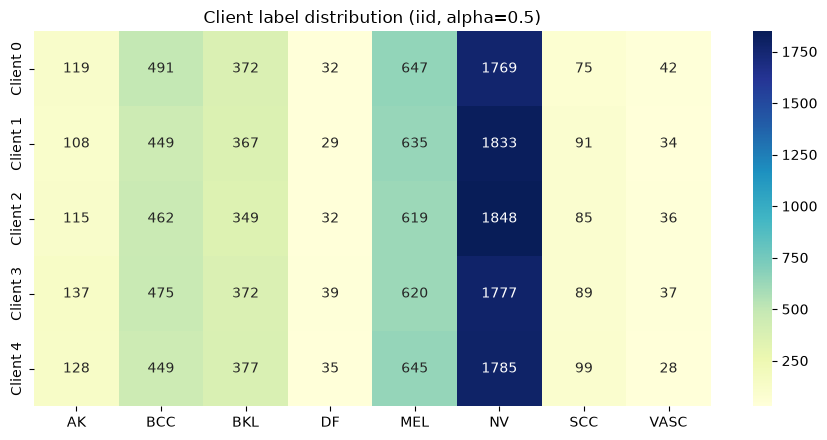

In [6]:
df_trainpool, df_test = train_test_split(df_all, test_size=TEST_FRAC,
                                         stratify=df_all["label"], random_state=SEED)
df_train, df_val = train_test_split(df_trainpool, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                    stratify=df_trainpool["label"], random_state=SEED)
df_train, df_val, df_test = (d.reset_index(drop=True) for d in (df_train, df_val, df_test))
log(f"Split: train {len(df_train)} | server-val {len(df_val)} | test {len(df_test)}")

def partition_indices(labels, n_clients, method, alpha, seed=SEED, min_size=20):
    """Split sample indices among clients: IID, or Dirichlet label-skew (non-IID)."""
    rng = np.random.default_rng(seed)
    if method == "iid":
        return [p.tolist() for p in np.array_split(rng.permutation(len(labels)), n_clients)]
    for _ in range(1000):
        parts = [[] for _ in range(n_clients)]
        for c in np.unique(labels):
            idx_c = rng.permutation(np.where(labels == c)[0])
            props = rng.dirichlet(alpha * np.ones(n_clients))
            cuts = (np.cumsum(props) * len(idx_c)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx_c, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            return parts
    raise RuntimeError("Could not create partitions; increase alpha or reduce NUM_CLIENTS")

parts = partition_indices(df_train["label"].values, NUM_CLIENTS, PARTITION, DIRICHLET_ALPHA)
CLIENT_DATA = []   # per client: (train_records, localval_records); record = (path, label)
for k, idx in enumerate(parts):
    d = df_train.iloc[idx]
    vc = d["label"].value_counts()
    strat = d["label"] if vc.min() >= 2 and int(len(d) * LOCAL_VAL_FRAC) >= len(vc) else None
    tr, va = train_test_split(d, test_size=LOCAL_VAL_FRAC, stratify=strat, random_state=SEED)
    CLIENT_DATA.append((list(zip(tr["path"], tr["label"])), list(zip(va["path"], va["label"]))))
    log(f"Client {k}: {len(tr)} train | {len(va)} local-val")

mat = np.zeros((NUM_CLIENTS, NUM_CLASSES), dtype=int)
for k, idx in enumerate(parts):
    for c, n in df_train.iloc[idx]["label"].value_counts().items():
        mat[k, c] = n
pd.DataFrame(mat, columns=CLASS_NAMES, index=[f"client_{k}" for k in range(NUM_CLIENTS)]).to_csv(
    OUTPUT_DIR / "client_partition.csv")
plt.figure(figsize=(9, 0.6 * NUM_CLIENTS + 1.5))
sns.heatmap(mat, annot=True, fmt="d", cmap="YlGnBu", xticklabels=CLASS_NAMES,
            yticklabels=[f"Client {k}" for k in range(NUM_CLIENTS)])
plt.title(f"Client label distribution ({PARTITION}, alpha={DIRICHLET_ALPHA})")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "client_partition.png", dpi=150); plt.show()

## 6. PyTorch Dataset and transforms

In [7]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(180),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.03),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.1))])
EVAL_TF = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.125)), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ISICDataset(Dataset):
    """Dataset over a list of (image_path, label) records."""
    def __init__(self, records, tf):
        self.records, self.tf = records, tf
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        path, label = self.records[i]
        with Image.open(path) as im:
            x = self.tf(im.convert("RGB"))
        return x, int(label)

def make_loader(records, train: bool, batch_size: int = BATCH_SIZE):
    return DataLoader(ISICDataset(records, TRAIN_TF if train else EVAL_TF),
                      batch_size=batch_size, shuffle=train,
                      drop_last=train and len(records) > batch_size,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

VAL_RECORDS  = list(zip(df_val["path"], df_val["label"]))
TEST_RECORDS = list(zip(df_test["path"], df_test["label"]))

## 7. Custom model — DermaFedNet
```
image 256×256 ─► ConvNeXt-Tiny encoder (ImageNet) ─► LayerNorm ─► CBAM (channel + spatial attention)
                                                                   ├─► GeM pooling ───────────────┐
                                                                   └─► 1×1 proj ─► 64 tokens       │
                                                                       + pos-embedding             │
                                                                       ─► 2× Transformer encoder   │
                                                                       ─► mean token ──────────────┤
                                                                      concat (768+384) ─► MLP ─► 8 classes
```

In [8]:
from torchvision.models.convnext import LayerNorm2d

class CBAM(nn.Module):
    """Convolutional Block Attention Module: channel attention followed by spatial attention."""
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        self.mlp = nn.Sequential(nn.Conv2d(channels, channels // reduction, 1), nn.GELU(),
                                 nn.Conv2d(channels // reduction, channels, 1))
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2)

    def forward(self, x):
        ca = torch.sigmoid(self.mlp(F.adaptive_avg_pool2d(x, 1)) + self.mlp(F.adaptive_max_pool2d(x, 1)))
        x = x * ca
        sa = torch.sigmoid(self.spatial(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))
        return x * sa

class GeM(nn.Module):
    """Generalised-mean pooling with a learnable exponent p (computed in float32 for AMP safety)."""
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p, self.eps = nn.Parameter(torch.ones(1) * p), eps

    def forward(self, x):
        with torch.autocast(device_type=x.device.type, enabled=False):
            p = self.p.float().clamp(1.0, 6.0)
            x = x.float().clamp(min=self.eps).pow(p)
            return F.adaptive_avg_pool2d(x, 1).pow(1.0 / p).flatten(1)

class DermaFedNet(nn.Module):
    def __init__(self, num_classes, img_size=256, pretrained=False,
                 embed_dim=384, depth=2, heads=6, drop=0.3):
        super().__init__()
        cnx = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1 if pretrained else None)
        self.backbone = cnx.features                       # 768 × (img/32) × (img/32)
        self.norm = cnx.classifier[0]                      # pretrained LayerNorm2d(768)
        c = 768
        self.cbam = CBAM(c)
        self.gem = GeM()
        self.proj = nn.Conv2d(c, embed_dim, 1)
        n_tokens = (img_size // 32) ** 2
        self.pos = nn.Parameter(torch.zeros(1, n_tokens, embed_dim))
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(embed_dim, heads, embed_dim * 2, dropout=0.1,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.transformer = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.tok_norm = nn.LayerNorm(embed_dim)
        self.head = nn.Sequential(nn.LayerNorm(c + embed_dim), nn.Dropout(drop),
                                  nn.Linear(c + embed_dim, 512), nn.GELU(), nn.Dropout(0.2),
                                  nn.Linear(512, num_classes))

    def forward(self, x):
        f = self.cbam(self.norm(self.backbone(x)))
        g = self.gem(f)                                         # local texture / colour statistics
        t = self.proj(f).flatten(2).transpose(1, 2) + self.pos  # (B, tokens, embed)
        t = self.tok_norm(self.transformer(t)).mean(1)          # global lesion context
        return self.head(torch.cat([g.float(), t.float()], 1))

    def param_groups(self):
        enc = list(self.backbone.parameters()) + list(self.norm.parameters())
        enc_ids = {id(p) for p in enc}
        head = [p for p in self.parameters() if id(p) not in enc_ids]
        return [{"params": enc, "lr": LR_BACKBONE, "name": "encoder"},
                {"params": head, "lr": LR_HEAD, "name": "head"}]

def build_model(pretrained=False):
    return DermaFedNet(NUM_CLASSES, IMG_SIZE, pretrained=pretrained)

# Template of the state_dict (names, shapes, dtypes): used to flatten/unflatten weights for encryption
_m = build_model(PRETRAINED)                              # also downloads the ImageNet weights once
TEMPLATE = [(k, tuple(v.shape), v.dtype) for k, v in _m.state_dict().items()]
N_PARAMS = sum(int(np.prod(s)) for _, s, _ in TEMPLATE)
with torch.no_grad():
    out = _m.eval()(torch.randn(2, 3, IMG_SIZE, IMG_SIZE))
log(f"{MODEL_NAME}: {sum(p.numel() for p in _m.parameters())/1e6:.2f}M parameters | "
    f"state size {N_PARAMS/1e6:.2f}M values | output {tuple(out.shape)}")
with open(OUTPUT_DIR / "model_architecture.txt", "w") as f:
    f.write(str(_m))
del _m, out; gc.collect()

DermaFedNet: 31.18M parameters | state size 31.18M values | output (2, 8)


6666

## 8. Privacy layer — X25519 keys, AES-256-GCM encryption, SHA-256 hashing, secure-aggregation masks
In this simulation all key pairs are generated in this notebook; in a real deployment each client keeps
its own private key on its own device. Only public-key fingerprints are saved to disk.

In [9]:
def _raw_keypair():
    sk = X25519PrivateKey.generate()
    sk_raw = sk.private_bytes(serialization.Encoding.Raw, serialization.PrivateFormat.Raw,
                              serialization.NoEncryption())
    pk_raw = sk.public_key().public_bytes(serialization.Encoding.Raw, serialization.PublicFormat.Raw)
    return sk_raw, pk_raw

SERVER_SK, SERVER_PK = _raw_keypair()
_client_keys = [_raw_keypair() for _ in range(NUM_CLIENTS)]
CLIENT_SK = [k[0] for k in _client_keys]      # each client uses only its own entry
CLIENT_PK = [k[1] for k in _client_keys]      # public keys (shared with everyone)
GROUP_KEY = AESGCM.generate_key(bit_length=256)  # downlink key (server -> all clients), set up once
SCALE = float(2 ** FIXED_POINT_BITS)

def _fp(b: bytes) -> str:
    return hashlib.sha256(b).hexdigest()[:16]

with open(OUTPUT_DIR / "public_key_fingerprints.json", "w") as f:
    json.dump({"server": _fp(SERVER_PK), **{f"client_{k}": _fp(pk) for k, pk in enumerate(CLIENT_PK)}},
              f, indent=2)

# NOTE: the cryptography classes are imported inside the functions below (not used as notebook globals),
# because these functions are shipped to Ray worker processes, which must import the library themselves.
def _aesgcm(key: bytes):
    from cryptography.hazmat.primitives.ciphers.aead import AESGCM
    return AESGCM(key)

def _hkdf(secret: bytes, info: str) -> bytes:
    from cryptography.hazmat.primitives import hashes
    from cryptography.hazmat.primitives.kdf.hkdf import HKDF
    return HKDF(algorithm=hashes.SHA256(), length=32, salt=None, info=info.encode()).derive(secret)

def _x25519(sk_raw: bytes, pk_raw: bytes) -> bytes:
    from cryptography.hazmat.primitives.asymmetric.x25519 import X25519PrivateKey, X25519PublicKey
    return X25519PrivateKey.from_private_bytes(sk_raw).exchange(X25519PublicKey.from_public_bytes(pk_raw))

def uplink_key_client(pid):   # client side: X25519(client_sk, server_pk)
    return _hkdf(_x25519(CLIENT_SK[pid], SERVER_PK), "fl-uplink-aes256")

def uplink_key_server(pid):   # server side: X25519(server_sk, client_pk) -> the same key
    return _hkdf(_x25519(SERVER_SK, CLIENT_PK[pid]), "fl-uplink-aes256")

def mask_seed(pid, peer, rnd):
    """Pairwise mask seed shared only by clients pid and peer (X25519 agreement), fresh every round."""
    i, j = sorted((pid, peer))
    return int.from_bytes(_hkdf(_x25519(CLIENT_SK[pid], CLIENT_PK[peer]), f"fl-mask|{i}|{j}|round{rnd}")[:16], "big")

def flatten_state(sd) -> np.ndarray:
    return np.concatenate([v.detach().cpu().double().numpy().ravel() for v in sd.values()])

def unflatten_state(flat: np.ndarray) -> "OrderedDict[str, torch.Tensor]":
    out, o = OrderedDict(), 0
    for k, shape, dtype in TEMPLATE:
        n = int(np.prod(shape))
        out[k] = torch.from_numpy(np.ascontiguousarray(flat[o:o + n]).reshape(shape)).to(dtype)
        o += n
    assert o == flat.size, "weight vector does not match the model template"
    return out

def pack(ciphertext: bytes, nonce: bytes, digest: bytes) -> ArrayRecord:
    return ArrayRecord({"ciphertext": Array(np.frombuffer(ciphertext, np.uint8).copy()),
                        "nonce": Array(np.frombuffer(nonce, np.uint8).copy()),
                        "sha256": Array(np.frombuffer(digest, np.uint8).copy())})

def unpack(rec: ArrayRecord):
    return (rec["ciphertext"].numpy().tobytes(), rec["nonce"].numpy().tobytes(),
            rec["sha256"].numpy().tobytes())

# ---- Downlink (server -> clients): global model, AES-256-GCM + SHA-256 ----
def encrypt_global(sd, phase: str, rnd: int):
    plain = flatten_state(sd).astype(np.float32).tobytes()
    digest = hashlib.sha256(plain).digest()
    nonce = os.urandom(12)
    ct = _aesgcm(GROUP_KEY).encrypt(nonce, plain, f"downlink|{phase}|round={rnd}".encode())
    return pack(ct, nonce, digest), {"mb": len(ct) / 2**20, "sha256": digest.hex()}

def decrypt_global(rec: ArrayRecord, phase: str, rnd: int):
    ct, nonce, digest = unpack(rec)
    plain = _aesgcm(GROUP_KEY).decrypt(nonce, ct, f"downlink|{phase}|round={rnd}".encode())  # authenticated
    if hashlib.sha256(plain).digest() != digest:
        raise ValueError("SHA-256 mismatch on the received global model")
    return unflatten_state(np.frombuffer(plain, np.float32).astype(np.float64))

# ---- Uplink (client -> server): masked fixed-point update, SHA-256, AES-256-GCM ----
def secure_encode_update(sd, n_k: int, pid: int, rnd: int, num_clients: int):
    """Encode n_k·w as fixed-point integers, add pairwise masks (they cancel in the server's sum),
    hash and encrypt. The server can decrypt the payload but only ever sees masked (random-looking) values."""
    q = np.rint(flatten_state(sd) * (n_k * SCALE)).astype(np.int64).view(np.uint64)
    for peer in range(num_clients):
        if peer == pid:
            continue
        mask = np.random.PCG64(mask_seed(pid, peer, rnd)).random_raw(q.size)   # uint64
        if pid < peer:
            q += mask          # modulo 2^64 arithmetic
        else:
            q -= mask
        del mask
    plain = q.tobytes(); del q
    digest = hashlib.sha256(plain).digest()
    nonce = os.urandom(12)
    ct = _aesgcm(uplink_key_client(pid)).encrypt(nonce, plain, f"uplink|client={pid}|round={rnd}".encode())
    return pack(ct, nonce, digest), {"mb": len(ct) / 2**20, "sha256": digest.hex()}

def secure_aggregate(contents, rnd: int, num_clients: int):
    """Server: decrypt + verify every client payload, sum the masked updates, divide by Σ n_k (FedAvg)."""
    total, n_total, info, seen = None, 0, [], set()
    for c in contents:
        m = next(iter(c.metric_records.values()))
        pid, n_k = int(m["partition-id"]), int(m["num-examples"])
        ct, nonce, digest = unpack(next(iter(c.array_records.values())))
        t0 = time.time()
        plain = _aesgcm(uplink_key_server(pid)).decrypt(nonce, ct, f"uplink|client={pid}|round={rnd}".encode())
        verified = hashlib.sha256(plain).digest() == digest
        if not verified:
            raise ValueError(f"SHA-256 verification failed for client {pid}")
        q = np.frombuffer(plain, np.uint64)
        # What the server can see of ONE client: masked values (sample-based magnitude, for the log only)
        seen_mag = float(np.abs(q[:200_000].view(np.int64).astype(np.float64)).mean() / SCALE / n_k)
        total = q.copy() if total is None else (total + q)          # wraps modulo 2^64
        n_total += n_k
        seen.add(pid)
        info.append({"client": pid, "n": n_k, "mb": len(ct) / 2**20, "sha256": digest.hex(),
                     "verified": verified, "decrypt_s": time.time() - t0, "server_view_mean_abs": seen_mag})
        del plain, q
    if seen != set(range(num_clients)):
        raise RuntimeError(f"Secure aggregation needs all {num_clients} clients; got {sorted(seen)}")
    flat = total.view(np.int64).astype(np.float64) / SCALE / n_total
    return flat, n_total, info

log(f"Keys ready: server + {NUM_CLIENTS} clients (X25519), AES-256-GCM, SHA-256, "
    f"fixed-point 2^-{FIXED_POINT_BITS}")

Keys ready: server + 5 clients (X25519), AES-256-GCM, SHA-256, fixed-point 2^-24


## 9. Training / evaluation helpers and metrics

In [10]:
def class_weights_from(records, num_classes):
    counts = np.bincount([l for _, l in records], minlength=num_classes).astype(float)
    w = np.where(counts > 0, np.sqrt(counts.sum() / (num_classes * np.maximum(counts, 1))), 0.0)
    w = w / w[counts > 0].mean()
    return torch.tensor(w, dtype=torch.float32)

def train_one_epoch(model, loader, opt, scaler, crit, device):
    model.train()
    amp = USE_AMP and device.type == "cuda"
    total, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            out = model(x)
            loss = crit(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update()
        total += loss.item() * y.size(0)
        correct += (out.argmax(1) == y).sum().item()
        n += y.size(0)
    return total / max(n, 1), correct / max(n, 1)

@torch.no_grad()
def predict(model, loader, device, tta=False):
    """Return (mean loss, labels, softmax probabilities). tta=True averages 4 flipped views."""
    model.to(device).eval()
    amp = USE_AMP and device.type == "cuda"
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        views = [x, x.flip(-1), x.flip(-2), x.flip(-1).flip(-2)] if tta else [x]
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            prob = torch.stack([torch.softmax(model(v).float(), 1) for v in views]).mean(0)
        loss += F.nll_loss(torch.log(prob.clamp_min(1e-8)), y, reduction="sum").item()
        ys.append(y.cpu()); ps.append(prob.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss / len(y), y, p

def compute_metrics(y, prob, num_classes):
    pred = prob.argmax(1)
    m = {"acc": accuracy_score(y, pred),
         "bal_acc": balanced_accuracy_score(y, pred),
         "precision_macro": precision_score(y, pred, average="macro", zero_division=0),
         "recall_macro": recall_score(y, pred, average="macro", zero_division=0),
         "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}
    try:
        m["auc_macro"] = roc_auc_score(y, prob, multi_class="ovr", average="macro",
                                       labels=list(range(num_classes)))
    except ValueError:
        m["auc_macro"] = float("nan")
    return m

def round_lr_factor(rnd):
    """Cosine decay of the base learning rates across federated rounds (1.0 -> 0.1)."""
    t = (rnd - 1) / max(1, NUM_ROUNDS - 1)
    return 0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * t))

def epoch_lr_factor(ep, total):
    """Cosine decay within one round's local epochs (1.0 -> LR_MIN_FACTOR)."""
    t = (ep - 1) / max(1, total - 1)
    return LR_MIN_FACTOR + (1 - LR_MIN_FACTOR) * 0.5 * (1 + math.cos(math.pi * t))

def append_csv(path: Path, row: dict):
    new = not path.exists()
    pd.DataFrame([row]).to_csv(path, mode="a", header=new, index=False)

def local_fit(model, pid, rnd, device):
    """Up to LOCAL_EPOCHS of local training with local early stopping; returns the best local epoch."""
    warnings.filterwarnings("ignore", category=UserWarning)   # runs inside a Ray worker process
    train_records, val_records = CLIENT_DATA[pid]
    torch.manual_seed(SEED + 1000 * rnd + pid)
    tl, vl = make_loader(train_records, True), make_loader(val_records, False)
    model.to(device)
    opt = torch.optim.AdamW(model.param_groups(), weight_decay=WEIGHT_DECAY)
    base_lrs = [g["lr"] * round_lr_factor(rnd) for g in opt.param_groups]
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP and device.type == "cuda")
    cw = class_weights_from(train_records, NUM_CLASSES).to(device) if USE_CLASS_WEIGHTS else None
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=LABEL_SMOOTHING)

    best = {"val_loss": float("inf")}
    best_state, wait, t0 = None, 0, time.time()
    for ep in range(1, LOCAL_EPOCHS + 1):
        for g, base in zip(opt.param_groups, base_lrs):
            g["lr"] = base * epoch_lr_factor(ep, LOCAL_EPOCHS)
        tr_loss, tr_acc = train_one_epoch(model, tl, opt, scaler, crit, device)
        va_loss, y, p = predict(model, vl, device)
        va_acc, va_bal = float((p.argmax(1) == y).mean()), balanced_accuracy_score(y, p.argmax(1))
        improved = va_loss < best["val_loss"] - 1e-4
        if improved:
            best = {"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                    "val_loss": va_loss, "val_acc": va_acc, "val_bal_acc": va_bal}
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
        append_csv(OUTPUT_DIR / "client_epoch_log.csv", {
            "round": rnd, "client": pid, "epoch": ep, "lr_encoder": opt.param_groups[0]["lr"],
            "lr_head": opt.param_groups[1]["lr"], "train_loss": tr_loss, "train_acc": tr_acc,
            "val_loss": va_loss, "val_acc": va_acc, "val_bal_acc": va_bal, "best": improved})
        stop = LOCAL_EARLY_STOP and wait >= LOCAL_PATIENCE
        if ep == 1 or ep % LOCAL_PRINT_EVERY == 0 or ep == LOCAL_EPOCHS or stop:
            log(f"      [Client {pid} | Round {rnd} | epoch {ep:2d}/{LOCAL_EPOCHS}] "
                f"train_loss {tr_loss:.4f} train_acc {tr_acc:.4f} | val_loss {va_loss:.4f} "
                f"val_acc {va_acc:.4f} val_bal_acc {va_bal:.4f}" + ("  *best*" if improved else ""))
        if stop:
            log(f"      [Client {pid} | Round {rnd}] early stop at epoch {ep}; "
                f"keeping best epoch {best['epoch']} (val_loss {best['val_loss']:.4f})")
            break
    if best_state is None:                     # e.g. NaN validation loss: keep the last epoch
        best = {"epoch": ep, "train_loss": tr_loss, "train_acc": tr_acc,
                "val_loss": va_loss, "val_acc": va_acc, "val_bal_acc": va_bal}
    else:
        model.load_state_dict(best_state)
    best.update(epochs_run=ep, minutes=(time.time() - t0) / 60)
    return best

## 10. Flower ClientApp — decrypt global model → local training → mask + hash + encrypt the update

In [11]:
client_app = ClientApp()

def _device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

@client_app.train()
def client_train(msg: Message, context: Context):
    pid = int(context.node_config["partition-id"])
    cfg = msg.content["config"]
    rnd = int(cfg["server-round"]) + int(cfg["round-offset"])     # global round number
    device = _device()

    # 1) verify (SHA-256) + decrypt (AES-256-GCM) the global model
    model = build_model(pretrained=False)
    model.load_state_dict(decrypt_global(msg.content["arrays"], "train", rnd))
    log(f"   >> Client {pid} | Round {rnd}: global model received, AES-GCM decrypted, SHA-256 verified OK "
        f"| local training (max {LOCAL_EPOCHS} epochs)")

    # 2) local training
    best = local_fit(model, pid, rnd, device)
    n_k = len(CLIENT_DATA[pid][0])

    # 3) secure update: fixed-point n_k·w + pairwise masks -> SHA-256 -> AES-256-GCM
    t0 = time.time()
    payload, up = secure_encode_update(model.state_dict(), n_k, pid, rnd, NUM_CLIENTS)
    log(f"   << Client {pid} | Round {rnd}: update masked + hashed + encrypted in {time.time() - t0:.1f}s "
        f"| {up['mb']:.1f} MB | SHA-256 {up['sha256'][:16]}...")

    metrics = MetricRecord({
        "partition-id": pid, "num-examples": n_k,
        "local_train_loss": best["train_loss"], "local_train_acc": best["train_acc"],
        "local_val_loss": best["val_loss"], "local_val_acc": best["val_acc"],
        "local_val_bal_acc": best["val_bal_acc"], "best_epoch": best["epoch"],
        "epochs_run": best["epochs_run"], "local_minutes": best["minutes"]})
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=RecordDict({"arrays": payload, "metrics": metrics}), reply_to=msg)

@client_app.evaluate()
def client_evaluate(msg: Message, context: Context):
    """Evaluate the NEW global model (after secure FedAvg) on this client's local-val split."""
    warnings.filterwarnings("ignore", category=UserWarning)
    pid = int(context.node_config["partition-id"])
    cfg = msg.content["config"]
    rnd = int(cfg["server-round"]) + int(cfg["round-offset"])
    device = _device()
    model = build_model(pretrained=False)
    model.load_state_dict(decrypt_global(msg.content["arrays"], "eval", rnd))
    loss, y, p = predict(model, make_loader(CLIENT_DATA[pid][1], False), device)
    content = RecordDict({"metrics": MetricRecord({
        "partition-id": pid, "num-examples": len(y),
        "global_val_loss": loss, "global_val_acc": float((p.argmax(1) == y).mean()),
        "global_val_bal_acc": balanced_accuracy_score(y, p.argmax(1))})})
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=content, reply_to=msg)

## 11. Secure FedAvg strategy + ServerApp

In [12]:
class SecureFedAvg(FedAvg):
    """FedAvg whose model traffic is encrypted both ways and whose aggregation is masked:
    the server only learns Σ n_k·w_k (the FedAvg numerator), never an individual client update."""

    def __init__(self, *args, round_offset=0, **kwargs):
        super().__init__(*args, **kwargs)
        self.round_offset = round_offset
        self.security = {}           # global round -> security info for the logs

    def _enc(self, server_round, arrays, phase):
        rnd = server_round + self.round_offset
        rec, info = encrypt_global(arrays.to_torch_state_dict(), phase, rnd)
        self.security.setdefault(rnd, {})[f"downlink_{phase}"] = info
        return rec

    def configure_train(self, server_round, arrays, config, grid):
        return super().configure_train(server_round, self._enc(server_round, arrays, "train"), config, grid)

    def configure_evaluate(self, server_round, arrays, config, grid):
        if self.fraction_evaluate == 0.0:
            return []
        return super().configure_evaluate(server_round, self._enc(server_round, arrays, "eval"), config, grid)

    def aggregate_train(self, server_round, replies):
        valid, errors = self._check_and_log_replies(replies, is_train=True)
        rnd = server_round + self.round_offset
        if errors or not valid:
            raise RuntimeError(f"Round {rnd}: {len(errors)} client(s) failed (see the client error above; "
                               f"CUDA out of memory -> reduce BATCH_SIZE). Secure aggregation needs all clients.")
        contents = [m.content for m in valid]
        t0 = time.time()
        flat, n_total, info = secure_aggregate(contents, rnd, NUM_CLIENTS)
        sd = unflatten_state(flat)
        self.security.setdefault(rnd, {}).update(
            uplink=info, n_total=n_total, aggregate_s=time.time() - t0,
            global_mean_abs=float(np.abs(flat).mean()), finite=bool(np.isfinite(flat).all()))
        metrics = self.train_metrics_aggr_fn(contents, self.weighted_by_key)
        return ArrayRecord(sd), metrics

HISTORY = []         # per round: GLOBAL metrics on server-val + LOCAL / client means + security summary
CLIENT_ROWS = []     # per round per client: LOCAL model vs GLOBAL model on the same client data
RUN_RESULT = {}

def _collect(records, weight_key):
    rows = []
    for rec in records:
        mr = next(iter(rec.metric_records.values()))
        rows.append({k: float(v) for k, v in mr.items()})
    rows.sort(key=lambda r: r["partition-id"])
    w = np.array([r[weight_key] for r in rows], dtype=float); w = w / w.sum()
    keys = [k for k in rows[0] if k not in ("partition-id", weight_key)]
    return rows, {k: float(sum(wi * r[k] for wi, r in zip(w, rows))) for k in keys}

def make_server_app(round_offset: int, initial_state, best_so_far: dict) -> ServerApp:
    server_app = ServerApp()

    @server_app.main()
    def main(grid: Grid, context: Context) -> None:
        eval_model = build_model(pretrained=False)
        val_loader = make_loader(VAL_RECORDS, False, BATCH_SIZE * 2)
        best = dict(best_so_far)
        stats = {}
        t_run = time.time()
        strategy = None

        def train_aggr(records, weight_key):
            stats["local"] = _collect(records, weight_key)
            return MetricRecord(stats["local"][1])

        def eval_aggr(records, weight_key):
            stats["global_on_clients"] = _collect(records, weight_key)
            return MetricRecord(stats["global_on_clients"][1])

        def central_evaluate(server_round, arrays):
            rnd = server_round + round_offset
            if server_round == 0 and round_offset > 0:
                return None                        # resumed run: round already evaluated earlier
            eval_model.load_state_dict(arrays.to_torch_state_dict())
            loss, y, p = predict(eval_model, val_loader, DEVICE)
            eval_model.cpu()
            m = compute_metrics(y, p, NUM_CLASSES)
            m.update(round=rnd, val_loss=loss, elapsed_min=(time.time() - t_run) / 60)
            local_rows, local_avg = stats.pop("local", ([], {}))
            glob_rows, glob_avg = stats.pop("global_on_clients", ([], {}))
            sec = strategy.security.get(rnd, {})
            nan = float("nan")
            m.update(local_train_loss=local_avg.get("local_train_loss", nan),
                     local_train_acc=local_avg.get("local_train_acc", nan),
                     local_val_acc=local_avg.get("local_val_acc", nan),
                     local_val_bal_acc=local_avg.get("local_val_bal_acc", nan),
                     global_client_val_acc=glob_avg.get("global_val_acc", nan),
                     secure_agg_seconds=sec.get("aggregate_s", nan))

            is_best = rnd > 0 and m[SELECT_METRIC] > best.get(SELECT_METRIC, -1.0)
            if is_best:
                best.update({SELECT_METRIC: m[SELECT_METRIC], "round": rnd})
                torch.save(eval_model.state_dict(), OUTPUT_DIR / "global_best.pt")
            if rnd > 0 and SAVE_EVERY_ROUND:
                torch.save(eval_model.state_dict(), OUTPUT_DIR / f"global_round_{rnd:02d}.pt")
            HISTORY.append(m)

            g_by_pid = {int(r["partition-id"]): r for r in glob_rows}
            for r in local_rows:
                pid = int(r["partition-id"]); g = g_by_pid.get(pid, {})
                CLIENT_ROWS.append({
                    "round": rnd, "client": pid, "n_train": int(r["num-examples"]),
                    "epochs_run": int(r["epochs_run"]), "best_epoch": int(r["best_epoch"]),
                    "local_minutes": r["local_minutes"],
                    "local_train_loss": r["local_train_loss"], "local_train_acc": r["local_train_acc"],
                    "local_val_loss": r["local_val_loss"], "local_val_acc": r["local_val_acc"],
                    "local_val_bal_acc": r["local_val_bal_acc"],
                    "global_val_acc": g.get("global_val_acc", nan),
                    "global_val_bal_acc": g.get("global_val_bal_acc", nan)})
            for u in sec.get("uplink", []):
                append_csv(OUTPUT_DIR / "security_log.csv", {
                    "round": rnd, "direction": "uplink", "client": u["client"], "n": u["n"],
                    "size_mb": round(u["mb"], 2), "sha256": u["sha256"], "verified": u["verified"],
                    "decrypt_s": round(u["decrypt_s"], 3), "server_view_mean_abs": u["server_view_mean_abs"]})
            for phase in ("train", "eval"):
                d = sec.get(f"downlink_{phase}")
                if d:
                    append_csv(OUTPUT_DIR / "security_log.csv", {
                        "round": rnd, "direction": f"downlink_{phase}", "client": "all", "n": "",
                        "size_mb": round(d["mb"], 2), "sha256": d["sha256"], "verified": "",
                        "decrypt_s": "", "server_view_mean_abs": ""})

            # ---------------- console / log summary ----------------
            bar = "─" * 110
            if rnd == 0:
                log(f"\n{bar}\n[{MODEL_NAME}] Round 0/{NUM_ROUNDS} — initial global model (before federated training)")
            else:
                log(f"\n{bar}\n[{MODEL_NAME}] Round {rnd}/{NUM_ROUNDS} summary  (run time {m['elapsed_min']:.1f} min)")
                d = sec.get("downlink_train", {})
                log(f" Secure downlink : global model AES-256-GCM {d.get('mb', 0):.1f} MB | "
                    f"SHA-256 {d.get('sha256', '')[:16]}… | verified by every client ✓")
                for u in sec.get("uplink", []):
                    log(f" Secure uplink   : Client {u['client']} | n={u['n']:5d} | {u['mb']:.1f} MB AES-256-GCM | "
                        f"SHA-256 {u['sha256'][:16]}… | decrypted + verified ✓ | server sees masked values "
                        f"(mean |x| ≈ {u['server_view_mean_abs']:.2e})")
                log(f" Secure FedAvg   : {len(sec.get('uplink', []))}/{NUM_CLIENTS} updates summed, pairwise masks "
                    f"cancelled ✓ (global mean |w| = {sec.get('global_mean_abs', nan):.4f}, finite={sec.get('finite')}) "
                    f"| Σn = {sec.get('n_total', 0)} | {sec.get('aggregate_s', nan):.1f}s")
                for row in [r for r in CLIENT_ROWS if r["round"] == rnd]:
                    log(f"   Client {row['client']} (n={row['n_train']:5d}) | LOCAL  epochs {row['epochs_run']:2d}/{LOCAL_EPOCHS} "
                        f"(best {row['best_epoch']:2d}) train_loss {row['local_train_loss']:.4f} "
                        f"train_acc {row['local_train_acc']:.4f} val_acc {row['local_val_acc']:.4f} "
                        f"| GLOBAL val_acc {row['global_val_acc']:.4f}")
                log(f"   LOCAL  models (weighted mean)  | train_loss {m['local_train_loss']:.4f}  "
                    f"train_acc {m['local_train_acc']:.4f}  val_acc {m['local_val_acc']:.4f}  "
                    f"val_bal_acc {m['local_val_bal_acc']:.4f}")
                log(f"   GLOBAL model on client val     | val_acc {m['global_client_val_acc']:.4f}")
            log(f"   GLOBAL model on server-val     | loss {loss:.4f}  acc {m['acc']:.4f}  bal_acc {m['bal_acc']:.4f}  "
                f"f1 {m['f1_macro']:.4f}  auc {m['auc_macro']:.4f}"
                + (f"   <- best {SELECT_METRIC} so far, saved" if is_best else ""))

            # save progress after every round (survives crashes)
            with open(OUTPUT_DIR / "round_history.json", "w") as f:
                json.dump(HISTORY, f, indent=2)
            pd.DataFrame(HISTORY).to_csv(OUTPUT_DIR / "round_history.csv", index=False)
            pd.DataFrame(CLIENT_ROWS).to_csv(OUTPUT_DIR / "client_round_metrics.csv", index=False)
            RUN_RESULT["best"] = dict(best)
            return MetricRecord({k: float(v) for k, v in m.items()})

        strategy = SecureFedAvg(
            round_offset=round_offset,
            fraction_train=1.0, fraction_evaluate=1.0,           # secure aggregation uses all clients
            min_train_nodes=NUM_CLIENTS, min_evaluate_nodes=NUM_CLIENTS, min_available_nodes=NUM_CLIENTS,
            train_metrics_aggr_fn=train_aggr, evaluate_metrics_aggr_fn=eval_aggr)
        result = strategy.start(
            grid=grid,
            initial_arrays=ArrayRecord(initial_state),
            num_rounds=NUM_ROUNDS - round_offset,
            timeout=72 * 3600,                                   # 50 local epochs x 5 clients can take hours
            train_config=ConfigRecord({"round-offset": round_offset}),
            evaluate_config=ConfigRecord({"round-offset": round_offset}),
            evaluate_fn=central_evaluate)
        torch.save(result.arrays.to_torch_state_dict(), OUTPUT_DIR / "global_final.pt")
        log(f"\n[{MODEL_NAME}] training finished | best server-val {SELECT_METRIC} "
            f"{best.get(SELECT_METRIC, float('nan')):.4f} at round {best.get('round')}")

    return server_app

## 12. Run privacy-preserving federated training
If the run stops (power cut, crash), just run this cell again: with RESUME = True it continues from the
last saved round (`global_round_XX.pt`).

In [13]:
backend_config = {
    "client_resources": {"num_cpus": CLIENT_NUM_CPUS, "num_gpus": CLIENT_NUM_GPUS},
    "init_args": {"include_dashboard": False, "log_to_driver": True},
}

round_offset, best_so_far = 0, {}
HISTORY, CLIENT_ROWS = [], []
saved = sorted(OUTPUT_DIR.glob("global_round_*.pt"))
if RESUME and saved and (OUTPUT_DIR / "round_history.json").exists():
    round_offset = int(saved[-1].stem.split("_")[-1])
    HISTORY = [h for h in json.load(open(OUTPUT_DIR / "round_history.json")) if h["round"] <= round_offset]
    if (OUTPUT_DIR / "client_round_metrics.csv").exists():
        CLIENT_ROWS = pd.read_csv(OUTPUT_DIR / "client_round_metrics.csv").query("round <= @round_offset").to_dict("records")
    done = [h for h in HISTORY if h["round"] > 0]
    if done:
        b = max(done, key=lambda h: h[SELECT_METRIC])
        best_so_far = {SELECT_METRIC: b[SELECT_METRIC], "round": int(b["round"])}
    initial_state = torch.load(saved[-1], map_location="cpu")
    log(f"RESUME: continuing after round {round_offset} (best so far: {best_so_far})")
else:
    # fresh run: remove results of any previous run in OUTPUT_DIR
    for f in ["client_epoch_log.csv", "security_log.csv", "round_history.json", "round_history.csv",
              "client_round_metrics.csv", "global_best.pt", "global_final.pt"] + [p.name for p in saved]:
        (OUTPUT_DIR / f).unlink(missing_ok=True)
    initial_state = build_model(pretrained=PRETRAINED).state_dict()

if round_offset >= NUM_ROUNDS:
    log("All rounds already finished — go to the evaluation cells.")
else:
    log(f"\n{'=' * 110}\nPrivacy-preserving FL | {MODEL_NAME} | {NUM_CLIENTS} clients | rounds "
        f"{round_offset + 1}-{NUM_ROUNDS} | up to {LOCAL_EPOCHS} local epochs | Secure FedAvg\n{'=' * 110}")
    seed_everything()
    t0 = time.time()
    run_simulation(server_app=make_server_app(round_offset, initial_state, best_so_far),
                   client_app=client_app, num_supernodes=NUM_CLIENTS, backend_config=backend_config)
    log(f"Total training time: {(time.time() - t0) / 3600:.2f} h")
del initial_state; gc.collect()


Privacy-preserving FL | DermaFedNet | 5 clients | rounds 1-50 | up to 50 local epochs | Secure FedAvg



            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator 


──────────────────────────────────────────────────────────────────────────────────────────────────────────────
[DermaFedNet] Round 0/50 — initial global model (before federated training)
   GLOBAL model on server-val     | loss 2.0112  acc 0.3987  bal_acc 0.1388  f1 0.0974  auc 0.4660
(ClientAppActor pid=40408)    >> Client 0 | Round 1: global model received, AES-GCM decrypted, SHA-256 verified OK | local training (max 50 epochs)


(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(raylet) Stack (most recent call first): [repeated 3x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en

(ClientAppActor pid=40408)       [Client 0 | Round 1 | epoch  1/50] train_loss 2.1004 train_acc 0.5249 | val_loss 1.2209 val_acc 0.6113 val_bal_acc 0.2448  *best*


...

(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memor

(ClientAppActor pid=40408)       [Client 4 | Round 50 | epoch  9/50] train_loss 0.9076 train_acc 0.9965 | val_loss 0.4773 val_acc 0.9324 val_bal_acc 0.8928
(ClientAppActor pid=40408)       [Client 4 | Round 50] early stop at epoch 9; keeping best epoch 3 (val_loss 0.4608)
(ClientAppActor pid=40408)    << Client 4 | Round 50: update masked + hashed + encrypted in 3.8s | 237.9 MB | SHA-256 6a6bccd96c1a8e79...


(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
(ClientAppActor pid=40408)   return data.pin_memory(device)
(ClientAppActor pid=40408) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memor


──────────────────────────────────────────────────────────────────────────────────────────────────────────────
[DermaFedNet] Round 50/50 summary  (run time 1348.9 min)
 Secure downlink : global model AES-256-GCM 118.9 MB | SHA-256 6d180a7b85d55172… | verified by every client ✓
 Secure uplink   : Client 0 | n= 3192 | 237.9 MB AES-256-GCM | SHA-256 0fb1632a82165e3b… | decrypted + verified ✓ | server sees masked values (mean |x| ≈ 8.61e+07)
 Secure uplink   : Client 1 | n= 3191 | 237.9 MB AES-256-GCM | SHA-256 e7d42f67a37a682e… | decrypted + verified ✓ | server sees masked values (mean |x| ≈ 8.60e+07)
 Secure uplink   : Client 2 | n= 3191 | 237.9 MB AES-256-GCM | SHA-256 99bac181a555d3ce… | decrypted + verified ✓ | server sees masked values (mean |x| ≈ 8.63e+07)
 Secure uplink   : Client 3 | n= 3191 | 237.9 MB AES-256-GCM | SHA-256 4867322be81b7165… | decrypted + verified ✓ | server sees masked values (mean |x| ≈ 8.62e+07)
 Secure uplink   : Client 4 | n= 3191 | 237.9 MB AES-256-GCM | SH

796

## 13. Learning curves — LOCAL vs GLOBAL, per round and per local epoch

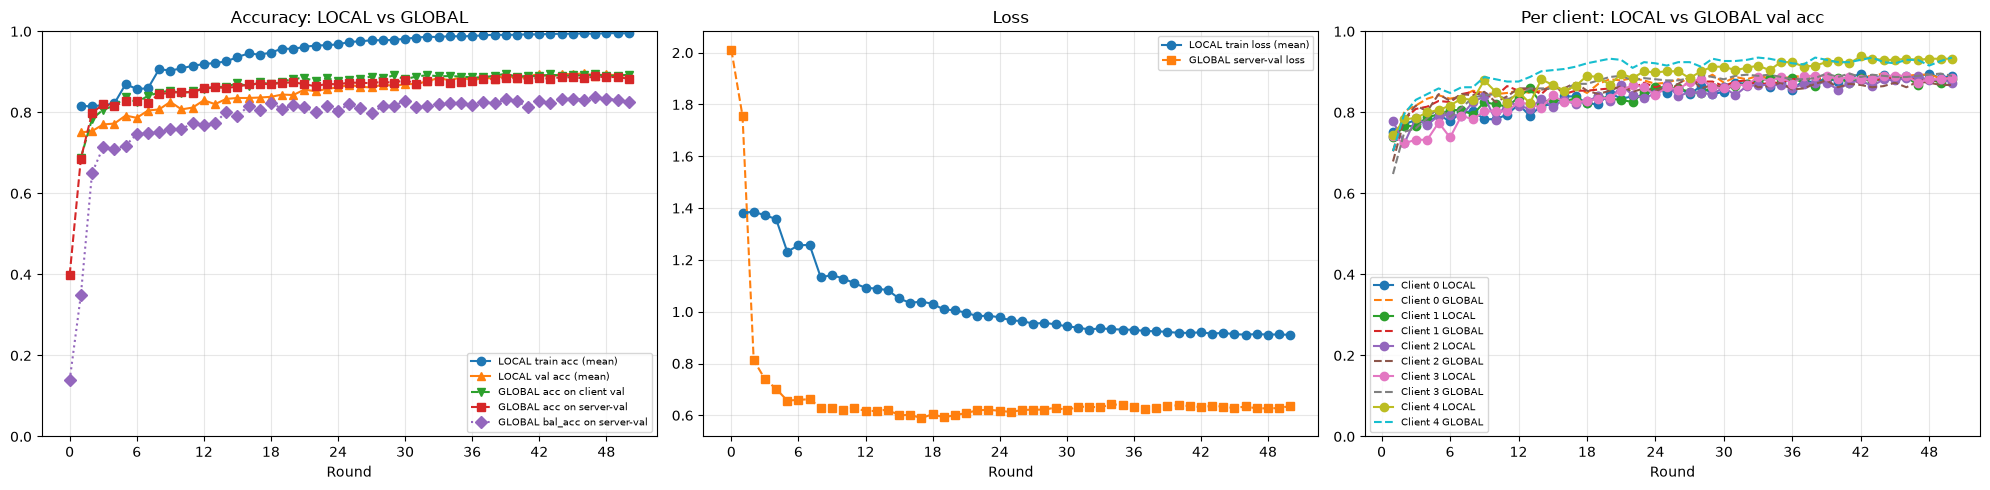

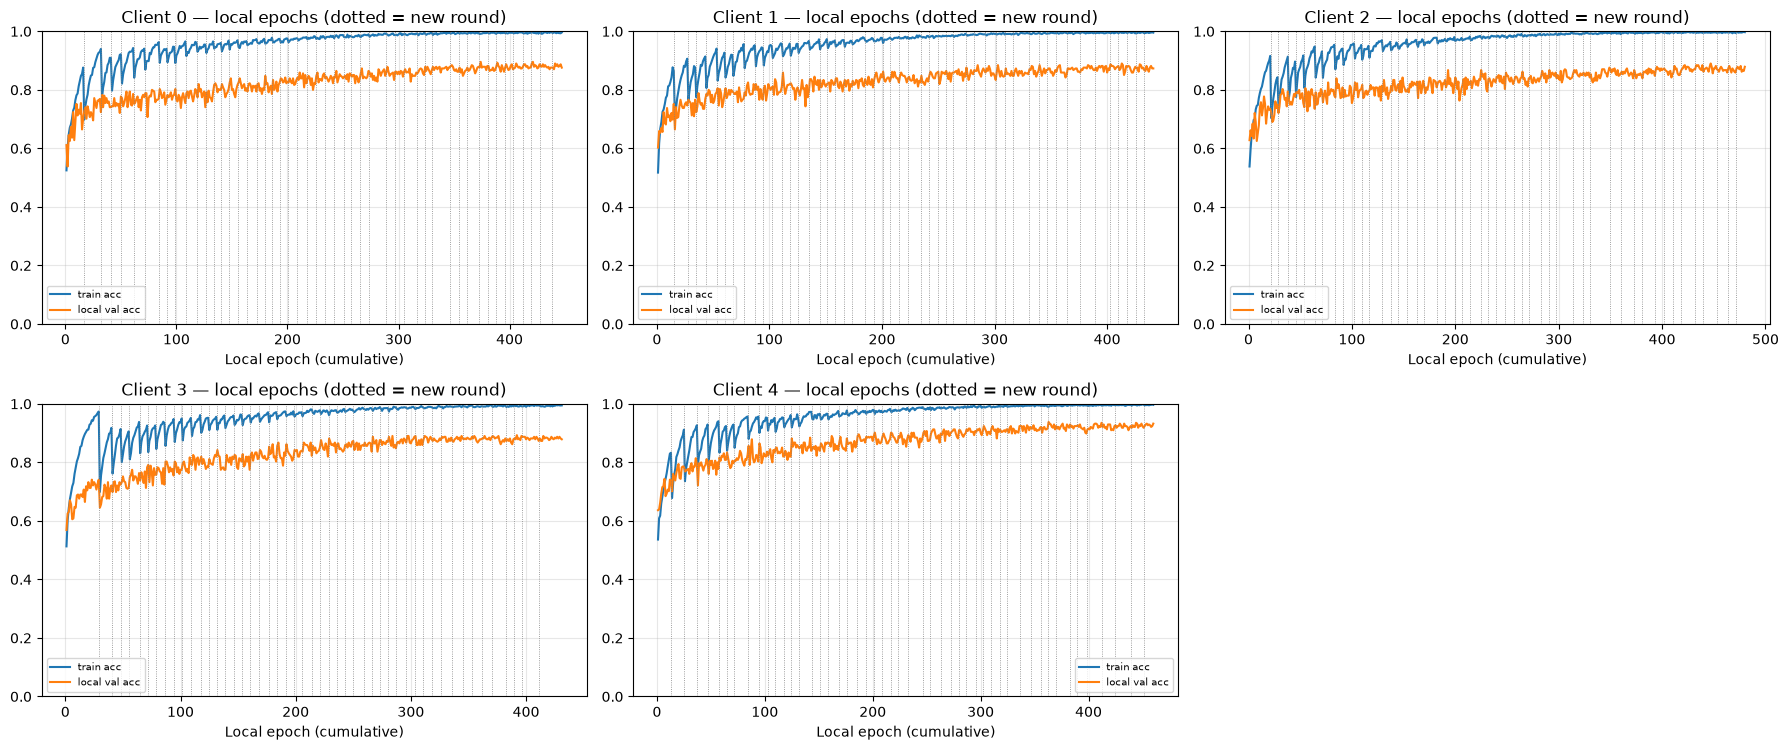

In [14]:
H = pd.DataFrame(json.load(open(OUTPUT_DIR / "round_history.json")))
CR = pd.read_csv(OUTPUT_DIR / "client_round_metrics.csv")
HR = H[H["round"] > 0]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(HR["round"], HR["local_train_acc"], "-o", label="LOCAL train acc (mean)")
axes[0].plot(HR["round"], HR["local_val_acc"], "-^", label="LOCAL val acc (mean)")
axes[0].plot(HR["round"], HR["global_client_val_acc"], "--v", label="GLOBAL acc on client val")
axes[0].plot(H["round"], H["acc"], "--s", label="GLOBAL acc on server-val")
axes[0].plot(H["round"], H["bal_acc"], ":D", label="GLOBAL bal_acc on server-val")
axes[0].set_title("Accuracy: LOCAL vs GLOBAL"); axes[0].set_ylim(0, 1)
axes[1].plot(HR["round"], HR["local_train_loss"], "-o", label="LOCAL train loss (mean)")
axes[1].plot(H["round"], H["val_loss"], "--s", label="GLOBAL server-val loss")
axes[1].set_title("Loss")
for c in sorted(CR["client"].unique()):
    d = CR[CR["client"] == c]
    axes[2].plot(d["round"], d["local_val_acc"], "-o", label=f"Client {c} LOCAL")
    axes[2].plot(d["round"], d["global_val_acc"], "--", label=f"Client {c} GLOBAL")
axes[2].set_title("Per client: LOCAL vs GLOBAL val acc"); axes[2].set_ylim(0, 1)
for ax in axes:
    ax.set_xlabel("Round"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "learning_curves_rounds.png", dpi=150); plt.show()

# Per-epoch local curves (all rounds concatenated) for every client
E = pd.read_csv(OUTPUT_DIR / "client_epoch_log.csv")
ncol = min(3, NUM_CLIENTS); nrow = math.ceil(NUM_CLIENTS / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 3.8 * nrow), squeeze=False)
for ax, c in zip(axes.flat, range(NUM_CLIENTS)):
    d = E[E["client"] == c].reset_index(drop=True)
    x = np.arange(1, len(d) + 1)
    ax.plot(x, d["train_acc"], label="train acc"); ax.plot(x, d["val_acc"], label="local val acc")
    for b in np.where(d["round"].diff().fillna(0) != 0)[0]:
        ax.axvline(b + 0.5, color="grey", lw=0.6, ls=":")        # round boundaries
    ax.set_title(f"Client {c} — local epochs (dotted = new round)"); ax.set_ylim(0, 1)
    ax.set_xlabel("Local epoch (cumulative)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
for ax in list(axes.flat)[NUM_CLIENTS:]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "learning_curves_local_epochs.png", dpi=150); plt.show()

## 14. Final held-out test evaluation of the best GLOBAL model (+ TTA) and save everything

c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\


FINAL TEST — DermaFedNet, best global model from round 47 (selected by acc)
  no_tta | acc 0.8772 | bal_acc 0.8041 | precision 0.8620 | recall 0.8041 | f1 0.8305 | auc 0.9240
  tta    | acc 0.8808 | bal_acc 0.8087 | precision 0.8650 | recall 0.8087 | f1 0.8345 | auc 0.9354
              precision    recall  f1-score   support

          AK     0.7857    0.6994    0.7401       173
         BCC     0.8846    0.9218    0.9028       665
         BKL     0.7788    0.7848    0.7818       525
          DF     0.9286    0.8125    0.8667        48
         MEL     0.8580    0.7688    0.8110       904
          NV     0.9129    0.9522    0.9321      2575
         SCC     0.8165    0.7063    0.7574       126
        VASC     0.9545    0.8235    0.8842        51

    accuracy                         0.8808      5067
   macro avg     0.8650    0.8087    0.8345      5067
weighted avg     0.8793    0.8808    0.8791      5067



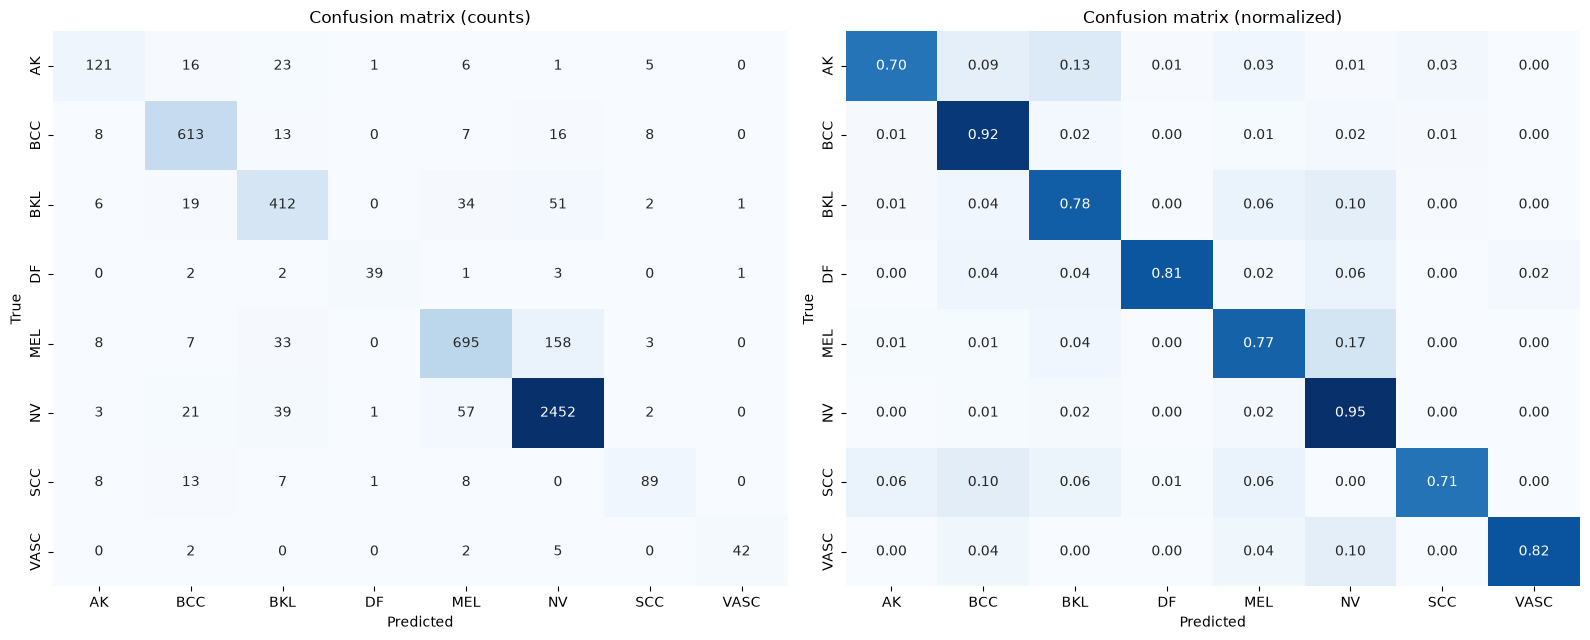

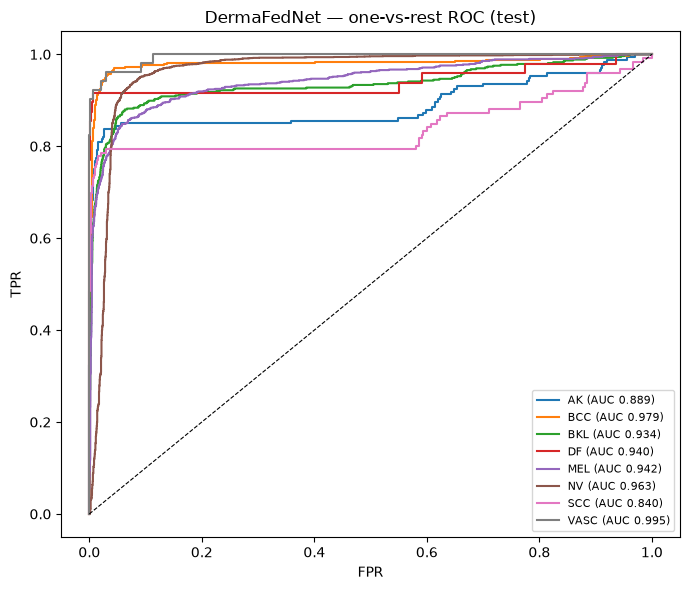


Saved files:
  class_distribution.png                        0.03 MB
  classification_report.txt                     0.00 MB
  client_epoch_log.csv                          0.33 MB
  client_partition.csv                          0.00 MB
  client_partition.png                          0.07 MB
  client_round_metrics.csv                      0.04 MB
  config.json                                   0.00 MB
  confusion_matrix.png                          0.13 MB
  global_best.pt                              119.02 MB
  global_final.pt                             119.01 MB
  global_round_01.pt                          119.02 MB
  global_round_02.pt                          119.02 MB
  global_round_03.pt                          119.02 MB
  global_round_04.pt                          119.02 MB
  global_round_05.pt                          119.02 MB
  global_round_06.pt                          119.02 MB
  global_round_07.pt                          119.02 MB
  global_round_08.pt              

In [15]:
best_model = build_model(pretrained=False)
best_model.load_state_dict(torch.load(OUTPUT_DIR / "global_best.pt", map_location="cpu"))
best_round = int(H.loc[HR[SELECT_METRIC].idxmax(), "round"])
test_loader = make_loader(TEST_RECORDS, False, BATCH_SIZE * 2)

results = {}
for name, tta in [("no_tta", False)] + ([("tta", True)] if USE_TTA else []):
    loss, y_test, p = predict(best_model, test_loader, DEVICE, tta=tta)
    results[name] = {"test_loss": loss, **compute_metrics(y_test, p, NUM_CLASSES)}
    if tta or not USE_TTA:
        p_final = p
final_key = "tta" if USE_TTA else "no_tta"
results["best_round"] = best_round
results["select_metric"] = SELECT_METRIC
with open(OUTPUT_DIR / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

report = classification_report(y_test, p_final.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0)
with open(OUTPUT_DIR / "classification_report.txt", "w") as f:
    f.write(f"{MODEL_NAME} — best global model (round {best_round}), test set, {final_key}\n\n{report}")
pred_df = pd.DataFrame({"path": [r[0] for r in TEST_RECORDS], "true": [CLASS_NAMES[i] for i in y_test],
                        "pred": [CLASS_NAMES[i] for i in p_final.argmax(1)]})
for i, c in enumerate(CLASS_NAMES):
    pred_df[f"prob_{c}"] = p_final[:, i]
pred_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

log(f"\n{'=' * 110}\nFINAL TEST — {MODEL_NAME}, best global model from round {best_round} (selected by {SELECT_METRIC})")
for name in [k for k in ("no_tta", "tta") if k in results]:
    r = results[name]
    log(f"  {name:6s} | acc {r['acc']:.4f} | bal_acc {r['bal_acc']:.4f} | precision {r['precision_macro']:.4f} | "
        f"recall {r['recall_macro']:.4f} | f1 {r['f1_macro']:.4f} | auc {r['auc_macro']:.4f}")
log(report)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, norm, fmt, title in [(axes[0], None, "d", "counts"), (axes[1], "true", ".2f", "normalized")]:
    cm = confusion_matrix(y_test, p_final.argmax(1), labels=range(NUM_CLASSES), normalize=norm)
    sns.heatmap(cm, annot=True, fmt=fmt, cmap="Blues", ax=ax, cbar=False,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"Confusion matrix ({title})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150); plt.show()

plt.figure(figsize=(7, 6))
for c in range(NUM_CLASSES):
    if (y_test == c).any():
        fpr, tpr, _ = roc_curve(y_test == c, p_final[:, c])
        plt.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} (AUC {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"{MODEL_NAME} — one-vs-rest ROC (test)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "roc_curves.png", dpi=150); plt.show()

log("\nSaved files:")
for p in sorted(OUTPUT_DIR.iterdir()):
    log(f"  {p.name:40s} {p.stat().st_size / 2**20:9.2f} MB")